# TrackML Dataset Exploration — Step 3

**⚠️ IMPORTANT DATA PROVENANCE NOTICE — READ FIRST ⚠️**

This notebook, by default, runs against a **`[SYNTHETIC DATA]`** fallback event, generated by
`scripts/generate_synthetic_event.py`. It is **NOT** real TrackML data. It exists only so that
this notebook can be executed end-to-end and reviewed, before real data has been downloaded.

Every output cell that shows numbers or plots derived from synthetic data is labeled
**`[SYNTHETIC DATA]`**. Nothing produced by this notebook in its current form should be quoted
in the course report as a real physics finding.

See `docs/DATA_ACCESS.md` for:
- why real data could not be downloaded in the environment that authored this notebook,
- exactly how to obtain the real dataset,
- how to point this notebook at real data (change one path in the config cell below — no other
  code changes needed, since the loader/physics code is identical for real and synthetic data).

---

### Scientific ground rules for this notebook (see also `src/truth_checks.py` docstrings)

1. The clustering algorithm (not yet built) must **never** receive `particle_id`, truth labels,
   or truth weights.
2. Truth is used here **only** for understanding, validation, and profiling — never as an input
   to any grouping decision.
3. No coordinate transformation is implemented in this notebook (deferred to a later step).
4. No clustering is implemented in this notebook (deferred to a later step).


## 0. Setup

In [1]:
import sys
from pathlib import Path

# Allow importing the src/ package when running from notebooks/
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root))

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import load_event, load_event_ids, profile_event, EventFilesNotFoundError
from src.physics import add_transverse_radius_and_phi, add_particle_pt
from src.truth_checks import run_all_checks, assert_core_invariants
from src.profiling import profile_events, layer_occupancy
from src.track_selection import (
    unambiguous_particle_ids, select_valid_tracks,
    get_track_hits, track_summary,
)
from scripts.generate_synthetic_event import generate_synthetic_event, write_synthetic_event

with open(project_root / "configs" / "data_exploration.yaml") as f:
    config = yaml.safe_load(f)

rng = np.random.default_rng(config["random_seed"])
print("Loaded config:")
print(yaml.dump(config))


Loaded config:
dataset:
  doi: 10.5281/zenodo.4730167
  license: CC-BY-4.0
  real_data_dir: data/raw
  source: zenodo
  synthetic_data_dir: data/interim/synthetic
  version: v1
profiling_event_ids:
- 1000
project_version: step3-dataset-exploration
random_seed: 42
single_event_inspection:
  event_id: 1000
track_visualization:
  n_particles_to_show: 8



In [2]:
# Determine whether real data is available; fall back to synthetic if not,
# printing a clear notice either way. This is the ONLY place in the notebook
# that decides real-vs-synthetic — everything below is identical either way.

real_dir = project_root / config["dataset"]["real_data_dir"]
synthetic_dir = project_root / config["dataset"]["synthetic_data_dir"]

USING_SYNTHETIC = False
try:
    available_ids = load_event_ids(str(real_dir))
    DATA_DIR = str(real_dir)
    print(f"[REAL DATA] Found {len(available_ids)} event(s) in {real_dir}")
except EventFilesNotFoundError:
    print(f"[NOTICE] No real data found at {real_dir}.")
    print("[NOTICE] Falling back to SYNTHETIC data for infrastructure demonstration.")
    print("[NOTICE] See docs/DATA_ACCESS.md to obtain real data.")
    USING_SYNTHETIC = True
    DATA_DIR = str(synthetic_dir)
    # Generate the configured profiling events if they don't already exist
    synthetic_dir.mkdir(parents=True, exist_ok=True)
    for i, eid in enumerate(config["profiling_event_ids"]):
        event = generate_synthetic_event(event_id=eid, n_particles=40, n_layers=6, seed=100 + eid)
        write_synthetic_event(str(synthetic_dir), event, event_id=eid)
    available_ids = load_event_ids(DATA_DIR)
    print(f"[SYNTHETIC DATA] Generated and wrote {len(available_ids)} synthetic event(s) to {synthetic_dir}")

DATA_LABEL = "[SYNTHETIC DATA]" if USING_SYNTHETIC else "[REAL DATA]"
print()
print(f"Using data source: {DATA_LABEL}  (path: {DATA_DIR})")


[REAL DATA] Found 1 event(s) in /home/claude/trackml-reconstruction/data/raw

Using data source: [REAL DATA]  (path: /home/claude/trackml-reconstruction/data/raw)


## 1. Load ONE Complete Event

In [3]:
EVENT_ID = config["single_event_inspection"]["event_id"]

event = load_event(DATA_DIR, EVENT_ID, parts=("hits", "particles", "truth"))
hits, particles, truth = event["hits"], event["particles"], event["truth"]

print(f"{DATA_LABEL} Loaded event_id={EVENT_ID}")
print(f"{DATA_LABEL} hits shape:      {hits.shape}")
print(f"{DATA_LABEL} particles shape: {particles.shape}")
print(f"{DATA_LABEL} truth shape:     {truth.shape}")


[REAL DATA] Loaded event_id=1000
[REAL DATA] hits shape:      (120939, 7)
[REAL DATA] particles shape: (12263, 9)
[REAL DATA] truth shape:     (120939, 9)


In [4]:
stats = profile_event(event)
print(f"{DATA_LABEL} Event {EVENT_ID} profile:")
for k, v in stats.items():
    print(f"  {k}: {v}")


[REAL DATA] Event 1000 profile:
  n_hits: 120939
  n_unique_hit_ids: 120939
  x_min: -1024.8399658203125
  x_max: 1025.3299560546875
  y_min: -1025.1099853515625
  y_max: 1024.8499755859375
  z_min: -2955.5
  z_max: 2955.5
  volume_id_min: 7
  volume_id_max: 18
  layer_id_min: 2
  layer_id_max: 14
  module_id_min: 1
  module_id_max: 3192
  n_truth_rows: 120939
  n_unique_truth_hit_ids: 120939
  n_noise_hits: 17634
  n_unique_nonzero_particle_ids: 2487
  n_particles: 12263
  n_reconstructable_particles_nhits_ge_1: 10565


### Verify basic invariants against actual files (not just documentation)

In [5]:
# Per the Step 3 spec: "Do not assume the documentation is correct until
# the actual file confirms it." This cell performs that confirmation.

print(f"{DATA_LABEL} len(hits) == len(truth): {len(hits) == len(truth)}")
print(f"{DATA_LABEL} hit_id sets match exactly: {set(hits['hit_id']) == set(truth['hit_id'])}")

particle_ids_in_truth = set(truth.loc[truth['particle_id'] != 0, 'particle_id'])
particle_ids_in_particles = set(particles['particle_id'])
print(f"{DATA_LABEL} nonzero truth particle_ids all present in particles.csv: "
      f"{particle_ids_in_truth.issubset(particle_ids_in_particles)}")

# This will raise AssertionError loudly (not silently fix) if violated
assert_core_invariants(event)
print(f"{DATA_LABEL} All core invariants (src/truth_checks.py) PASSED.")


[REAL DATA] len(hits) == len(truth): True
[REAL DATA] hit_id sets match exactly: True
[REAL DATA] nonzero truth particle_ids all present in particles.csv: True
[REAL DATA] All core invariants (src/truth_checks.py) PASSED.


## 2. Truth Sanity Checks (full report)

In [6]:
import json
report = run_all_checks(event)
print(f"{DATA_LABEL} Full truth sanity check report:")
print(json.dumps(report, indent=2, default=str))


[REAL DATA] Full truth sanity check report:
{
  "hit_id_uniqueness": {
    "hits_hit_id_unique": true,
    "truth_hit_id_unique": true,
    "n_hits": 120939,
    "n_unique_hit_ids_in_hits": 120939,
    "n_truth_rows": 120939,
    "n_unique_hit_ids_in_truth": 120939
  },
  "every_hit_has_truth": {
    "len_hits_equals_len_truth": true,
    "n_hits": 120939,
    "n_truth_rows": 120939,
    "n_hit_ids_missing_from_truth": 0,
    "n_truth_hit_ids_missing_from_hits": 0,
    "hit_ids_missing_from_truth_sample": [],
    "truth_hit_ids_missing_from_hits_sample": []
  },
  "noise_hits": {
    "n_noise_hits_particle_id_zero": 17634,
    "n_unique_nonzero_particle_ids": 2487,
    "noise_fraction": 0.14580904422890878
  },
  "hits_per_particle_histogram": {
    "particles_with_0_hits": 0,
    "particles_with_1_hit": 19,
    "particles_with_2_hits": 8,
    "particles_with_3_hits": 6,
    "particles_with_4_or_more_hits": 2454,
    "total_nonzero_particles_observed_in_truth": 2487
  },
  "particles_n

## 3. Derived Physics Quantities

Using `src/physics.py` — only the simple, verified formulas: transverse radius `r`, azimuthal
angle `phi`, and particle-level transverse momentum `pT`. **No coordinate transformation is
computed here.**


In [7]:
hits_with_derived = add_transverse_radius_and_phi(hits)
particles_with_pt = add_particle_pt(particles)

print(f"{DATA_LABEL} hits with derived columns:")
display(hits_with_derived[['hit_id', 'x', 'y', 'z', 'transverse_radius', 'phi']].head())

print(f"\n{DATA_LABEL} particle pT summary statistics:")
display(particles_with_pt['pt'].describe())


[REAL DATA] hits with derived columns:


,hit_id,x,y,z,transverse_radius,phi
0,1,-64.409897,-7.163700,-1502.5,64.807045,-3.030828
1,2,-55.336102,0.635342,-1502.5,55.339748,3.130112
2,3,-83.830498,-1.143010,-1502.5,83.838287,-3.127959
3,4,-96.109100,-8.241030,-1502.5,96.461777,-3.056055
4,5,-62.673599,-9.371200,-1502.5,63.370335,-2.993168



[REAL DATA] particle pT summary statistics:


count    12263.000000
mean         0.554168
std          0.983781
min          0.100058
25%          0.216707
50%          0.359845
75%          0.625855
max         55.592354
Name: pt, dtype: float64

## 4. First Visualizations (ONE complete event)

### 4a. All hits — x vs y

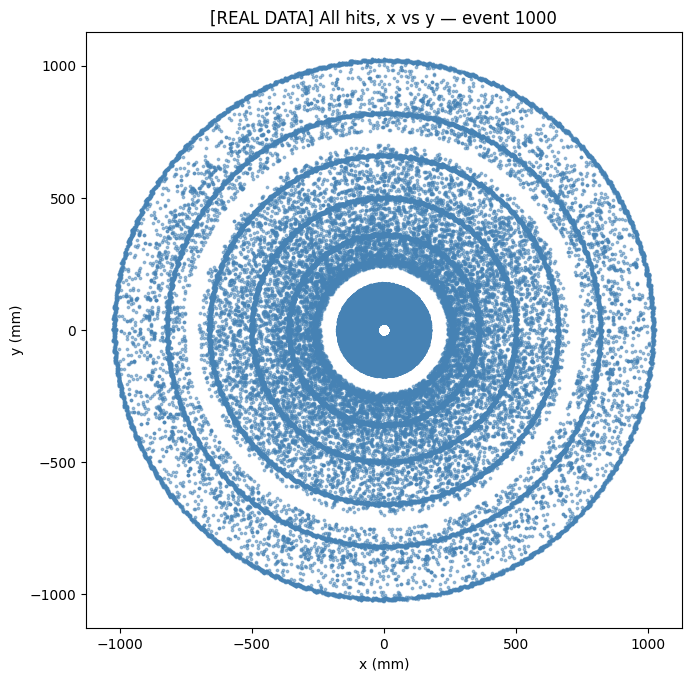

[REAL DATA] This plot uses ONLY hits.csv (x, y). No truth information was used.


In [8]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(hits['x'], hits['y'], s=3, alpha=0.5, color='steelblue')
ax.set_xlabel('x (mm)')
ax.set_ylabel('y (mm)')
ax.set_title(f'{DATA_LABEL} All hits, x vs y — event {EVENT_ID}')
ax.set_aspect('equal')
plt.tight_layout()
plt.show()
print(f"{DATA_LABEL} This plot uses ONLY hits.csv (x, y). No truth information was used.")


### 4b. z vs transverse radius

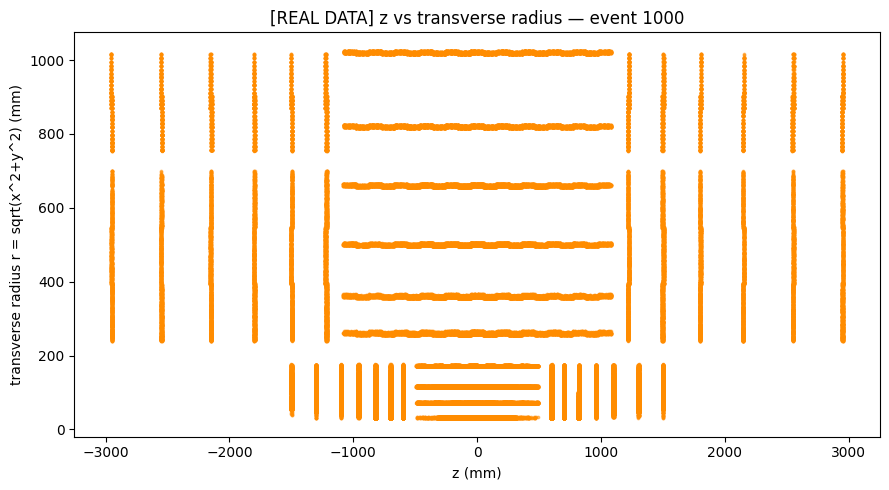

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(hits_with_derived['z'], hits_with_derived['transverse_radius'], s=3, alpha=0.5, color='darkorange')
ax.set_xlabel('z (mm)')
ax.set_ylabel('transverse radius r = sqrt(x^2+y^2) (mm)')
ax.set_title(f'{DATA_LABEL} z vs transverse radius — event {EVENT_ID}')
plt.tight_layout()
plt.show()


### 4c. phi vs transverse radius

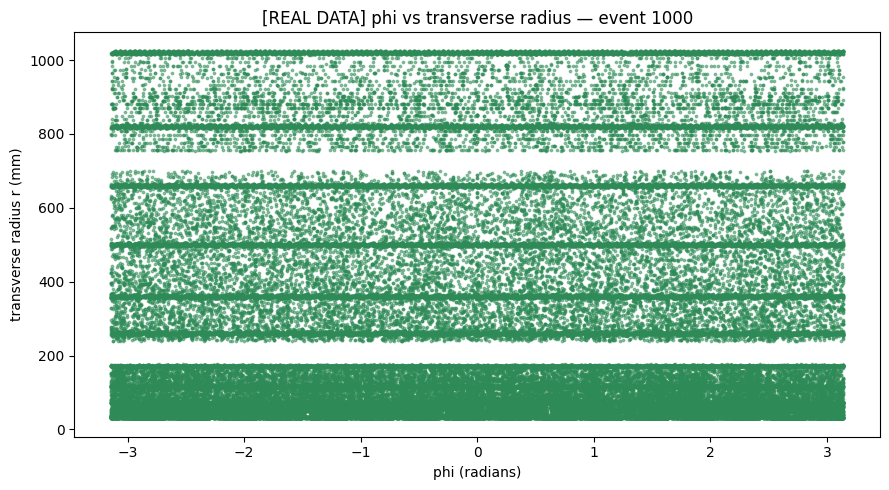

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(hits_with_derived['phi'], hits_with_derived['transverse_radius'], s=3, alpha=0.5, color='seagreen')
ax.set_xlabel('phi (radians)')
ax.set_ylabel('transverse radius r (mm)')
ax.set_title(f'{DATA_LABEL} phi vs transverse radius — event {EVENT_ID}')
plt.tight_layout()
plt.show()


### 4d. Hit-count distribution per particle

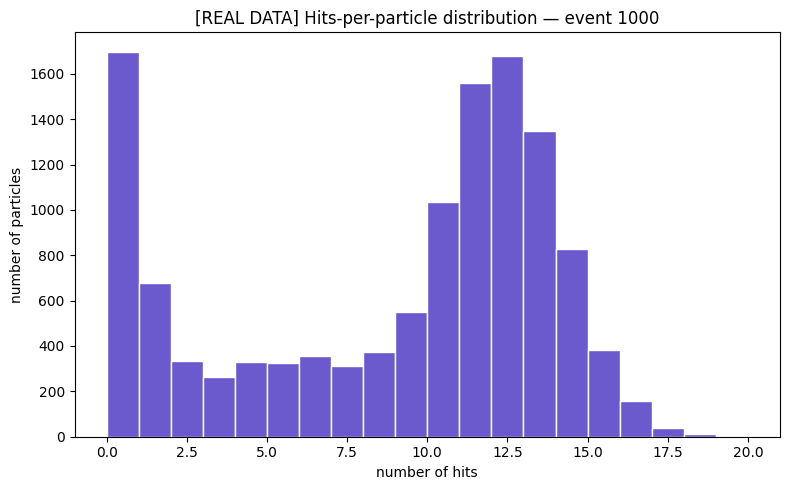

In [11]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(particles['nhits'], bins=range(0, particles['nhits'].max() + 2), color='slateblue', edgecolor='white')
ax.set_xlabel('number of hits')
ax.set_ylabel('number of particles')
ax.set_title(f'{DATA_LABEL} Hits-per-particle distribution — event {EVENT_ID}')
plt.tight_layout()
plt.show()


### 4e. pT distribution of particles

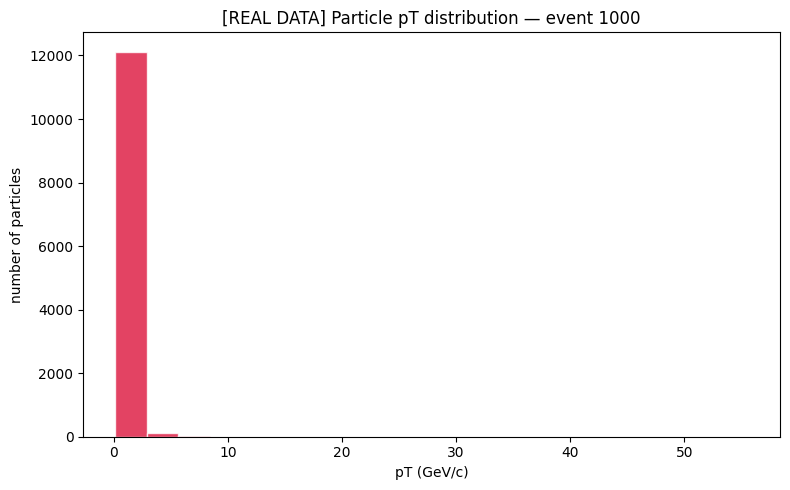

In [12]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(particles_with_pt['pt'], bins=20, color='crimson', edgecolor='white', alpha=0.8)
ax.set_xlabel('pT (GeV/c)')
ax.set_ylabel('number of particles')
ax.set_title(f'{DATA_LABEL} Particle pT distribution — event {EVENT_ID}')
plt.tight_layout()
plt.show()


### 4f. Number of hits by detector layer

,volume_id,layer_id,n_hits
0,7,2,1449
1,7,4,1767
2,7,6,2165
3,7,8,2553
4,7,10,2887
5,7,12,3028
6,7,14,3024
7,8,2,8892
8,8,4,7484
9,8,6,6672


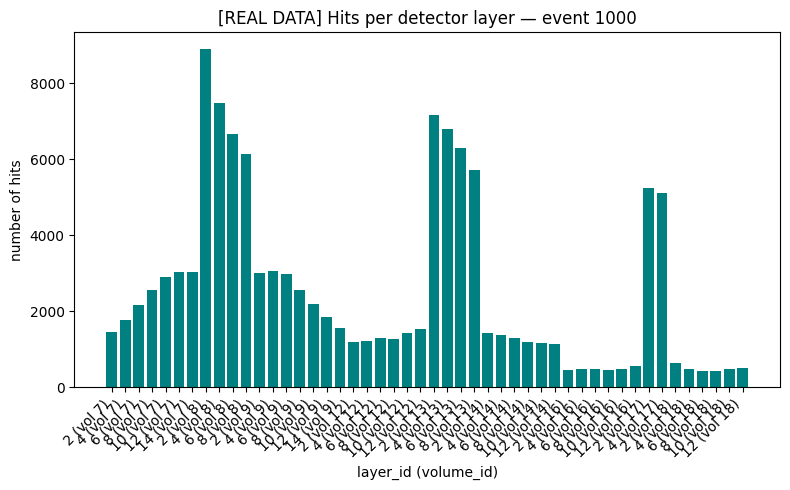

In [13]:
occ = layer_occupancy(DATA_DIR, EVENT_ID)
display(occ)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(occ['layer_id'].astype(str) + ' (vol ' + occ['volume_id'].astype(str) + ')', occ['n_hits'], color='teal')
ax.set_xlabel('layer_id (volume_id)')
ax.set_ylabel('number of hits')
ax.set_title(f'{DATA_LABEL} Hits per detector layer — event {EVENT_ID}')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


### 4g. Number of hits by detector volume

[REAL DATA] Hits by volume_id:


volume_id
7     16873
8     29172
9     17186
12     7931
13    25990
14     7585
16     2915
17    10356
18     2931
dtype: int64

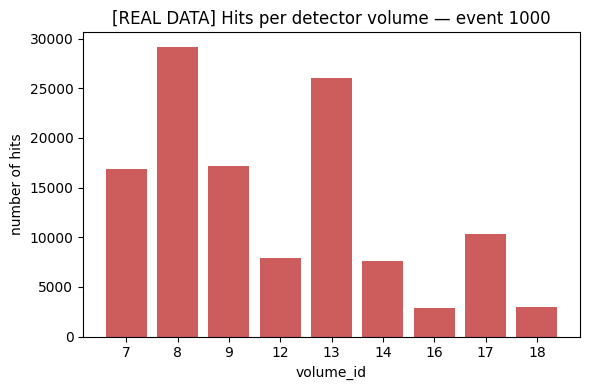

In [14]:
volume_counts = hits.groupby('volume_id').size()
print(f"{DATA_LABEL} Hits by volume_id:")
display(volume_counts)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(volume_counts.index.astype(str), volume_counts.values, color='indianred')
ax.set_xlabel('volume_id')
ax.set_ylabel('number of hits')
ax.set_title(f'{DATA_LABEL} Hits per detector volume — event {EVENT_ID}')
plt.tight_layout()
plt.show()

if USING_SYNTHETIC:
    print()
    print("[NOTICE] The synthetic generator only produces a single fake volume_id (=1),")
    print("[NOTICE] unlike the real detector's multiple volumes (Step 2, Part C). This plot")
    print("[NOTICE] will look trivially flat until run against real data.")


## 5. Truth-Colored Visualization (validation only)

**This visualization is for understanding/validation ONLY.**
**The colors (particle identity) must NEVER be passed into a clustering algorithm.**
We select a small subset of particles here purely so the plot is legible.


### ⚠️ M3 real-data finding — read before this section

On real data (event 1000), we found `particle_id` is **not** a unique key
in `particles.csv` (12,263 rows, only 2,564 unique IDs — up to 16 rows can
share one ID, representing genuinely different physical particles,
confirmed via distinct production vertices and momenta). See
`src/track_selection.py` module docstring and
`docs/PROJECT_CONTENT_MASTER.md` Section P.1 for the full investigation.

**Fix applied below:** trajectory visualization now selects only from
`particle_id` values that are unambiguous (exactly one row in
`particles.csv`) via `select_valid_tracks()`, rather than sampling from
all particle_ids. This is a diagnostic-visualization restriction — it does
**not** claim the underlying ambiguity is solved dataset-wide.


[REAL DATA] Valid (unambiguous, nhits>=4) particle rows available: 751 out of 2564 unique particle_id values in this event
[REAL DATA] Selected particle_ids for truth-colored plot: [np.int64(4510330000000000), np.int64(4510540000000000), np.int64(27022000000000000), np.int64(27023800000000000), np.int64(63056700000000000), np.int64(67555900000000000), np.int64(94578200000000000), np.int64(355798000000000000)]

[REAL DATA] Per-track diagnostic summary:
  particle_id=4510330000000000: n_hits=12, pT=2.163 GeV/c, q=1, r=[32.5,1022.3]mm, z=[15.9,498.8]mm, phi_spread=0.135 rad
  particle_id=67555900000000000: n_hits=16, pT=0.292 GeV/c, q=1, r=[39.7,99.5]mm, z=[-1502.0,-597.5]mm, phi_spread=0.059 rad
  particle_id=355798000000000000: n_hits=5, pT=0.244 GeV/c, q=-1, r=[39.5,53.3]mm, z=[1297.5,1502.0]mm, phi_spread=0.234 rad
  particle_id=63056700000000000: n_hits=15, pT=0.589 GeV/c, q=-1, r=[31.5,870.3]mm, z=[52.4,1502.5]mm, phi_spread=0.424 rad
  particle_id=27022000000000000: n_hits=15, pT=0

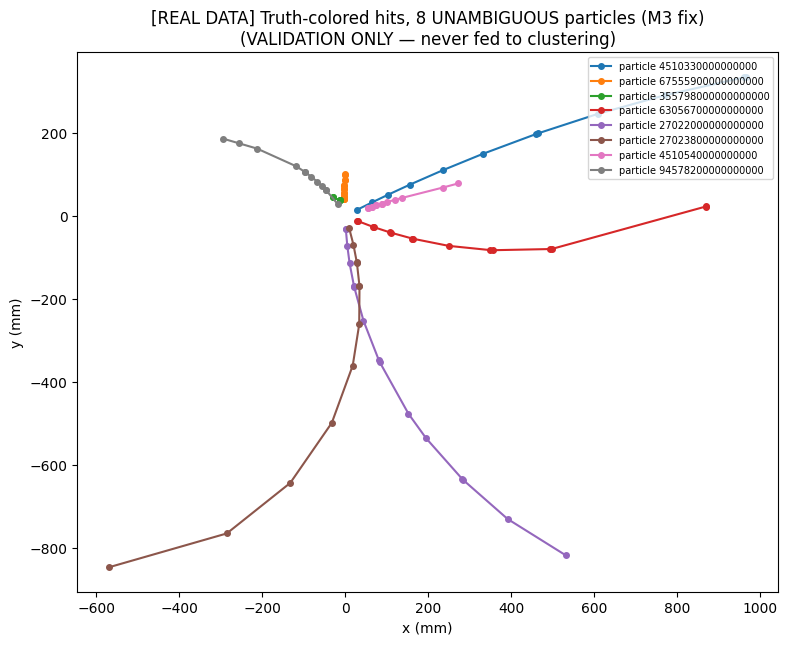

In [15]:
N_SHOW = config['track_visualization']['n_particles_to_show']

# M3 FIX: select only from UNAMBIGUOUS particle_ids (exactly one row in
# particles.csv) and with sufficient hits (official ORDER_MIN_HITS=4),
# using src/track_selection.py rather than sampling from all particle_ids
# naively. See markdown cell above.
valid_tracks = select_valid_tracks(particles, min_hits=4)
print(f"{DATA_LABEL} Valid (unambiguous, nhits>=4) particle rows available: {len(valid_tracks)} "
      f"out of {particles['particle_id'].nunique()} unique particle_id values in this event")

selected_particle_ids = rng.choice(
    valid_tracks['particle_id'].values, size=min(N_SHOW, len(valid_tracks)), replace=False
)
print(f"{DATA_LABEL} Selected particle_ids for truth-colored plot: {sorted(selected_particle_ids)}")

# Print a diagnostic summary for each selected track (M3 requirement:
# report particle/instance identifier, n_hits, pT, charge, radial range,
# z range for each selected trajectory)
print()
print(f"{DATA_LABEL} Per-track diagnostic summary:")
summaries = []
for pid in selected_particle_ids:
    s = track_summary(particles, hits, truth, int(pid))
    summaries.append(s)
    print(f"  particle_id={s['particle_id']}: n_hits={s['n_hits']}, pT={s['pt']:.3f} GeV/c, "
          f"q={s['charge']}, r=[{s['r_min']:.1f},{s['r_max']:.1f}]mm, "
          f"z=[{s['z_min']:.1f},{s['z_max']:.1f}]mm, phi_spread={s['phi_spread']:.3f} rad")

# Build the plotting subset using the FIXED per-particle retrieval
# (get_track_hits), which correctly isolates each particle_id's hits and
# sorts by transverse_radius (not z -- see M2/M3 ordering fix).
subset_frames = []
for pid in selected_particle_ids:
    t = get_track_hits(hits, truth, int(pid))
    t['particle_id'] = pid
    subset_frames.append(t)
import pandas as pd
subset = pd.concat(subset_frames, ignore_index=True)

fig, ax = plt.subplots(figsize=(8, 8))
for pid in selected_particle_ids:
    track_hits = subset[subset['particle_id'] == pid]
    ax.plot(track_hits['x'], track_hits['y'], marker='o', markersize=4, label=f'particle {pid}')
ax.set_xlabel('x (mm)')
ax.set_ylabel('y (mm)')
ax.set_title(f'{DATA_LABEL} Truth-colored hits, {len(selected_particle_ids)} UNAMBIGUOUS particles (M3 fix)\n'
             f'(VALIDATION ONLY \u2014 never fed to clustering)')
ax.legend(fontsize=7, loc='upper right')
ax.set_aspect('equal')
plt.tight_layout()
plt.show()


## 6. Track Visualization — "What does a real trajectory look like?"

Same selected particles as above, ordered along z, showing x/y and z/transverse-radius views.


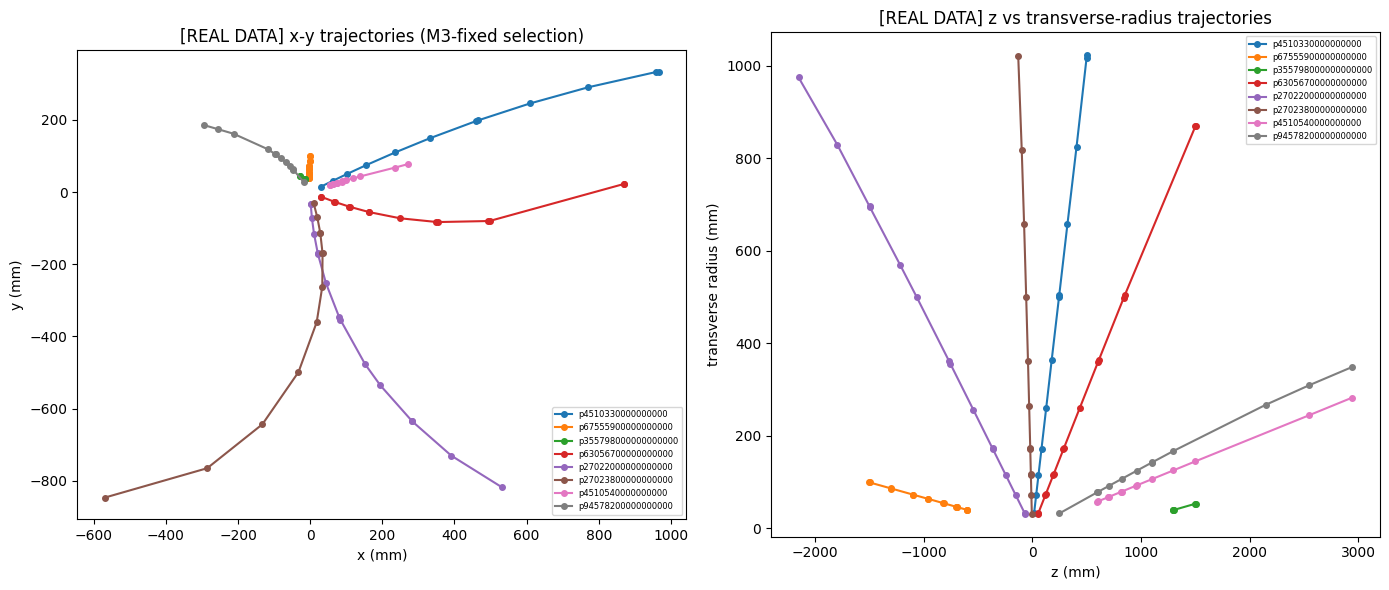

[REAL DATA] No coordinate transformation applied. No clustering performed.
[REAL DATA] This is raw (x,y,z) truth-grouped data, for visual understanding only.
[REAL DATA] All 8 trajectories drawn from UNAMBIGUOUS particle_ids (M3 fix).


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for pid in selected_particle_ids:
    track_hits = subset[subset['particle_id'] == pid]  # already sorted by transverse_radius
    axes[0].plot(track_hits['x'], track_hits['y'], marker='o', markersize=4, label=f'p{pid}')
    axes[1].plot(track_hits['z'], track_hits['transverse_radius'], marker='o', markersize=4, label=f'p{pid}')

axes[0].set_xlabel('x (mm)'); axes[0].set_ylabel('y (mm)')
axes[0].set_title(f'{DATA_LABEL} x-y trajectories (M3-fixed selection)'); axes[0].set_aspect('equal')

axes[1].set_xlabel('z (mm)'); axes[1].set_ylabel('transverse radius (mm)')
axes[1].set_title(f'{DATA_LABEL} z vs transverse-radius trajectories')

for ax in axes:
    ax.legend(fontsize=6)
plt.tight_layout()
plt.show()

print(f"{DATA_LABEL} No coordinate transformation applied. No clustering performed.")
print(f"{DATA_LABEL} This is raw (x,y,z) truth-grouped data, for visual understanding only.")
print(f"{DATA_LABEL} All {len(selected_particle_ids)} trajectories drawn from UNAMBIGUOUS particle_ids (M3 fix).")


## 7. Multi-Event Profiling

In [17]:
profiling_ids = config['profiling_event_ids']

# Ensure all configured events exist (generate any missing synthetic ones)
if USING_SYNTHETIC:
    existing = set(load_event_ids(DATA_DIR))
    for eid in profiling_ids:
        if eid not in existing:
            ev = generate_synthetic_event(event_id=eid, n_particles=40, n_layers=6, seed=100 + eid)
            write_synthetic_event(DATA_DIR, ev, event_id=eid)

profile_table = profile_events(DATA_DIR, profiling_ids)
print(f"{DATA_LABEL} Profiling table for events {profiling_ids}:")
display(profile_table)


[REAL DATA] Profiling table for events [1000]:


,n_hits,n_non_noise_hits,n_particles,n_reconstructable_particles,avg_hits_per_reconstructable_particle,median_hits_per_reconstructable_particle,max_hits_per_particle,noise_fraction
event_id,,,,,,,,
1000,120939,103305,12263,10565,9.778041,11.0,19,0.145809


## Summary

This notebook has **not**:
- implemented the TrackML coordinate transformation,
- implemented or run any clustering algorithm,
- implemented the TrackML scoring metric,
- chosen a final project subsample size.

It **has**:
- loaded one complete event (no truncation) via the official `trackml` library, wrapped by
  `src/data_loader.py`,
- verified core invariants directly against the loaded files rather than trusting documentation,
- computed simple, unit-tested derived quantities (`transverse_radius`, `phi`, `pT`),
- produced the required first visualizations,
- produced a multi-event profiling table.

**Every number and plot above is clearly labeled** as either `[REAL DATA]` or
`[SYNTHETIC DATA]`. If this notebook was run without real data present, **no output above should
be treated as a real physics finding** — see `docs/DATA_ACCESS.md` for how to supply real data.
